<a href="https://colab.research.google.com/github/swathi9876/breast_cancer_detection_using_decentralization/blob/main/logistic(non_iid).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving ank.csv to ank.csv



FEDAVG----Number of clients: 2
Round 1, Accuracy: 0.3726
Round 2, Accuracy: 0.3726
Round 3, Accuracy: 0.3726
Round 4, Accuracy: 0.3726
Round 5, Accuracy: 0.3761
Round 6, Accuracy: 0.6309
Round 7, Accuracy: 0.8471
Round 8, Accuracy: 0.7399
Round 9, Accuracy: 0.9016
Round 10, Accuracy: 0.8770

FEDAVG----Number of clients: 3
Round 1, Accuracy: 0.3726
Round 2, Accuracy: 0.3726
Round 3, Accuracy: 0.3726
Round 4, Accuracy: 0.6327
Round 5, Accuracy: 0.3726
Round 6, Accuracy: 0.3726
Round 7, Accuracy: 0.3726
Round 8, Accuracy: 0.3726
Round 9, Accuracy: 0.3726
Round 10, Accuracy: 0.3726

FEDAVG----Number of clients: 4
Round 1, Accuracy: 0.3726
Round 2, Accuracy: 0.6274
Round 3, Accuracy: 0.3726
Round 4, Accuracy: 0.3726
Round 5, Accuracy: 0.4780
Round 6, Accuracy: 0.8963
Round 7, Accuracy: 0.6415
Round 8, Accuracy: 0.3726
Round 9, Accuracy: 0.3726
Round 10, Accuracy: 0.8981

FEDAVG----Number of clients: 5
Round 1, Accuracy: 0.6274
Round 2, Accuracy: 0.6415
Round 3, Accuracy: 0.3726
Round 4, Ac

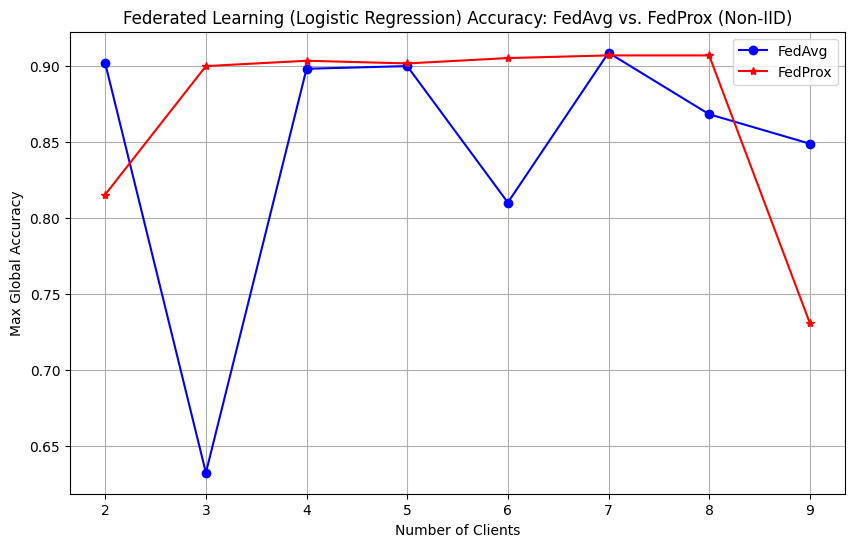

In [20]:
# Install necessary libraries
!pip install torch numpy syft
!pip install pandas matplotlib seaborn

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import copy

# Define the Logistic Regression model
class LogisticRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        out = self.linear(x)
        return out

# Load and preprocess the dataset
def preprocess_data(data_path):
    data = pd.read_csv(data_path)
    data = data.dropna()

    # Label encoding for the target variable
    label_encoder = LabelEncoder()
    data['diagnosis'] = label_encoder.fit_transform(data['diagnosis'])
    data = data.drop(data.columns[0], axis=1)

    # Split features and labels
    X = data.iloc[:, 1:].values.astype(np.float32)
    y = data.iloc[:, 0].values.astype(np.int64)
    return X, y

# Robust Non-IID Splitting using Dirichlet Distribution
def split_data_non_iid(X, y, num_clients, alpha=0.5):
    unique_classes = np.unique(y)
    num_classes = len(unique_classes)

    client_indices = [[] for _ in range(num_clients)]

    # Distribute samples of each class dynamically
    for cls in unique_classes:
        cls_indices = np.where(y == cls)[0]
        np.random.shuffle(cls_indices)

        # Use Dirichlet distribution to obtain non-iid proportions for each client
        proportions = np.random.dirichlet([alpha] * num_clients)
        proportions = (proportions * len(cls_indices)).astype(int)

        # Correct any rounding differences to ensure all samples are assigned
        difference = len(cls_indices) - sum(proportions)
        for d in range(difference):
            proportions[d % num_clients] += 1

        current_idx = 0
        for client_id, count in enumerate(proportions):
            client_indices[client_id].extend(cls_indices[current_idx:current_idx + count])
            current_idx += count

    client_data = []
    for indices in client_indices:
        np.random.shuffle(indices)
        client_data.append((X[indices], y[indices]))

    return client_data

# Create a federated dataset
def create_federated_dataset(client_data):
    federated_data = []
    for X, y in client_data:
        federated_data.append({'X': torch.tensor(X, dtype=torch.float32),
                               'y': torch.tensor(y, dtype=torch.long)})
    return federated_data

# Define the FedAvg algorithm
def federated_average(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict

def fedprox(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict

# Main simulation runner
def run_logistic_federated_simulation(algorithm_name, mu=0.01):
    num_rounds = 10
    input_dim = 30
    output_dim = 2

    # Preprocessing the dataset
    X, y = preprocess_data("ank.csv")

    cl, acc = [], []
    for i in range(2, 10):
        client_data = split_data_non_iid(X, y, i, alpha=0.5)
        print(f"\n{algorithm_name.upper()}----Number of clients: {i}")
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = LogisticRegression(input_dim, output_dim)

        for round in range(num_rounds):
            client_models = []
            global_model_copy = copy.deepcopy(model)

            for client_data_batch in federated_data:
                # Avoid training if dataset is empty
                if len(client_data_batch['X']) == 0:
                    continue

                local_model = LogisticRegression(input_dim, output_dim)
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.CrossEntropyLoss()

                # Performing local training
                for epoch in range(10):
                    optimizer.zero_grad()
                    outputs = local_model(client_data_batch['X'])
                    loss = criterion(outputs, client_data_batch['y'])

                    if algorithm_name.lower() == 'fedprox':
                        # Calculating the L2 proximal term for FedProx
                        proximal_term = 0.0
                        for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                            proximal_term += torch.sum((local_param - global_param.detach()) ** 2)
                        loss = loss + (mu / 2) * proximal_term

                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Aggregating client models
            if len(client_models) > 0:
                if algorithm_name.lower() == 'fedprox':
                    averaged_state_dict = fedprox(model, client_models)
                else:
                    averaged_state_dict = federated_average(model, client_models)
                model.load_state_dict(averaged_state_dict)

            # Calculating global accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                _, predicted = torch.max(outputs, 1)
                accuracy = (predicted == torch.tensor(y, dtype=torch.long)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy:.4f}')

        acc.append(max_acc)
    return cl, acc

def main():
    # Running both simulations(fed avg and fed prox simultaneously)
    cl_avg, acc_avg = run_logistic_federated_simulation('fedavg')
    cl_prox, acc_prox = run_logistic_federated_simulation('fedprox', mu=0.01)

    # Plotting unified results
    plt.figure(figsize=(10, 6))
    plt.plot(cl_avg, acc_avg, marker='o', label='FedAvg', color='blue')
    plt.plot(cl_prox, acc_prox, marker='*', label='FedProx', color='red')
    plt.xlabel('Number of Clients')
    plt.ylabel('Max Global Accuracy')
    plt.title('Federated Learning (Logistic Regression) Accuracy: FedAvg vs. FedProx (Non-IID)')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    main()